<a href="https://colab.research.google.com/github/sarwathasan72-svg/Masai_IIT_AIML/blob/main/AIRBnBCancellation_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Build Airbnb's Cancellation Predictor
**Sunday Workshop · run every cell top to bottom, in order.**

Labels: **I do** = the instructor runs it, **We do** = we run it together, **You do** = fill the `____` blanks yourself.

> **About the data.** Airbnb does not publish its bookings. We use a real, public set of **hotel** bookings (Portugal, 2015 to 2017) as a stand-in. The ideas are identical; the numbers are not Airbnb's.

In [ ]:
import os, re, sys, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

SEED = 42                      # fixed so every student gets the same numbers
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", __import__("sklearn").__version__)

pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1


## Part 1 · A host's problem
**Instructor:** open airbnb.co.in, open any listing, and scroll to **Cancellation policy**. Then picture the host's calendar.

Talk about it with the room:
* A guest cancels **two days** before check-in. What did the host lose?
* A guest cancels **three months** before. Is that the same loss? Why not?
* What would you want to know about a booking to guess whether it will cancel late?

Write three booking details on the board. They will be the model's **features**.

In [ ]:
bookings = pd.read_csv("hotel_bookings.csv")          # upload hotel_bookings.csv to Colab first
print("rows, columns:", bookings.shape)
bookings[["hotel", "lead_time", "arrival_date_month", "stays_in_week_nights", "adults",
          "market_segment", "deposit_type", "customer_type", "adr"]].head(5)

rows, columns: (119390, 32)


,hotel,lead_time,arrival_date_month,stays_in_week_nights,adults,market_segment,deposit_type,customer_type,adr
0,Resort Hotel,342,July,0,2,Direct,No Deposit,Transient,0.0
1,Resort Hotel,737,July,0,2,Direct,No Deposit,Transient,0.0
2,Resort Hotel,7,July,1,1,Direct,No Deposit,Transient,75.0
3,Resort Hotel,13,July,1,1,Corporate,No Deposit,Transient,75.0
4,Resort Hotel,14,July,2,2,Online TA,No Deposit,Transient,98.0


`lead_time` = days between booking and arrival. `adr` = price per night in euros. Every row is one real booking.

## Part 2 · Ask an AI to spot the risky bookings
Twenty real bookings are below. You see only what the host knew **when the booking was made**. Exactly **two** of them were cancelled in the final 14 days before arrival. The outcome is hidden.

In [ ]:
AI_ROWS = [7964, 11842, 26469, 34058, 42768, 43295, 63373, 65473, 67541, 72416,
           72977, 77903, 78307, 78400, 93460, 102118, 105293, 107225, 109161, 110616]
view = bookings.loc[AI_ROWS, ["hotel", "lead_time", "arrival_date_month", "stays_in_weekend_nights",
                              "stays_in_week_nights", "adults", "market_segment", "deposit_type",
                              "customer_type", "previous_cancellations", "is_repeated_guest", "adr"]].copy()
view["nights"] = view.stays_in_weekend_nights + view.stays_in_week_nights
view["arrives"] = view.arrival_date_month.str[:3]
view = view.drop(columns=["stays_in_weekend_nights", "stays_in_week_nights", "arrival_date_month"])
view.insert(0, "booking_id", range(1, 21))
view.set_index("booking_id")

,hotel,lead_time,adults,market_segment,deposit_type,customer_type,previous_cancellations,is_repeated_guest,adr,nights,arrives
booking_id,,,,,,,,,,,
1,Resort Hotel,116,2,Online TA,No Deposit,Transient,0,0,199.00,1,Sep
2,Resort Hotel,104,2,Direct,No Deposit,Transient,0,0,121.50,5,Jun
3,Resort Hotel,26,2,Online TA,No Deposit,Transient,0,0,192.00,2,Jul
4,Resort Hotel,171,2,Groups,No Deposit,Transient-Party,0,0,71.00,7,Mar
5,City Hotel,87,2,Corporate,No Deposit,Transient-Party,0,0,100.00,1,Sep
6,City Hotel,16,1,Direct,No Deposit,Group,0,0,132.67,3,Sep
7,City Hotel,45,2,Online TA,No Deposit,Transient,0,0,95.40,2,Feb
8,City Hotel,112,2,Offline TA/TO,Non Refund,Transient,0,0,95.00,2,Apr
9,City Hotel,28,2,Online TA,No Deposit,Transient,0,0,169.00,3,May


**Instructor:** paste this into ChatGPT or Claude, with the table above, and read its answer to the room.

> *Below are 20 hotel bookings with details known when each was made. Exactly 2 of them were cancelled in the final 14 days before arrival. Which 3 bookings are the most likely to be those late cancellations? Give the booking ids.*

Students can run it in their own tab too. The AI's answer was also recorded in advance, so every class sees the same one. **Do not look at the outcomes yet.**

In [ ]:
# Recorded in advance from an AI chat that saw only the table above. Same for every class.
AI_PICKS = [7964, 72977, 72416]          # row labels of the 3 bookings it chose
print("AI chose booking ids:", [AI_ROWS.index(i) + 1 for i in AI_PICKS])

my_picks = []        # OPTIONAL: type the three booking ids YOU would pick, e.g. [3, 7, 12]

AI chose booking ids: [1, 11, 10]


## Part 3 · How a classifier is judged, by hand
Now reveal what really happened.

In [ ]:
LATE_CANCELLED = [42768, 77903]          # the two bookings cancelled within 14 days of arrival (built properly in Part 4)

check = pd.DataFrame({"booking_id": range(1, 21)}, index=AI_ROWS)
check["cancelled_late"] = [1 if i in LATE_CANCELLED else 0 for i in AI_ROWS]
check["AI flagged"] = [1 if i in AI_PICKS else 0 for i in AI_ROWS]
check.set_index("booking_id").T

booking_id,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
cancelled_late,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
AI flagged,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0


Four boxes tell the whole story. Count them:

|  | Really cancelled late | Did not |
|---|---|---|
| **AI flagged** | TP, true positive | FP, false alarm |
| **AI did not flag** | FN, missed cancel | TN, correct all-clear |

In [ ]:
tp = int(((check["AI flagged"] == 1) & (check["cancelled_late"] == 1)).sum())
fp = int(((check["AI flagged"] == 1) & (check["cancelled_late"] == 0)).sum())
fn = int(((check["AI flagged"] == 0) & (check["cancelled_late"] == 1)).sum())
tn = int(((check["AI flagged"] == 0) & (check["cancelled_late"] == 0)).sum())
print("TP", tp, "| FP", fp, "| FN", fn, "| TN", tn)

accuracy = (tp + tn) / 20
print(f"\nAccuracy of the AI's picks: {accuracy:.0%}")
print(f"Accuracy of 'nobody will cancel': {(20 - 2) / 20:.0%}")

TP 0 | FP 3 | FN 2 | TN 15

Accuracy of the AI's picks: 75%
Accuracy of 'nobody will cancel': 90%


**Say it in host words.**
* **Precision** = of the guests we flag, how many really cancel late? *Low precision = we bother many guests for nothing.*
* **Recall** = of the guests who really cancel late, how many did we catch? *Low recall = empty nights we never saw coming.*

**You do:** fill the two blanks (each is one of `tp`, `fp`, `fn`, `tn`).

In [ ]:
precision = tp / (tp + fp) if (tp + fp) else 0
recall = tp / (tp + fn) if (tp + fn) else 0
print(f"Precision: {precision:.0%}   Recall: {recall:.0%}")

Precision: 0%   Recall: 0%


**Discuss:** "nobody will cancel" scores **90% accuracy** and catches **zero** cancellations. The AI's picks score *lower* than that and also caught none. **When one outcome is rare, accuracy rewards doing nothing.** That is why we use precision and recall.

## Part 4 · Look at the real data, then clean it
**Rule: never train on data you have not looked at.**

In [ ]:
print("rows, columns:", bookings.shape)
print("share cancelled at any time:", round(bookings.is_canceled.mean(), 3))
print("exact duplicate rows:", bookings.duplicated().sum())
print("\nmissing values (columns that have any):")
print(bookings.isna().sum()[lambda s: s > 0])
print("\nreservation_status counts:")
print(bookings.reservation_status.value_counts())

rows, columns: (119390, 32)
share cancelled at any time: 0.37


exact duplicate rows: 31994

missing values (columns that have any):


children         4
country        488
agent        16340
company     112593
dtype: int64

reservation_status counts:
reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64


**I do · Step 1: duplicate rows.** The file has no booking id, so identical rows may be copies. A copy in both train and test lets the model 'predict' something it already saw. (Real group bookings can look identical too, so this is a judgement call, and we will test it in Part 8.)

In [ ]:
n_raw = len(bookings)
data = bookings.drop_duplicates().copy()            # keeps the original row labels
print("rows:", n_raw, "->", len(data))

rows: 119390 -> 87396


**We do · Step 2: define what we predict.** We care about **late** cancellations, the ones a host cannot refill. We call a booking a *last-minute cancel* if it was cancelled **14 days or fewer before arrival**.

We need the arrival date and the cancellation date. For cancelled bookings, `reservation_status_date` is the day it was cancelled. (We use it **only to build the answer column**, never as an input. Remember this for Part 8.)

In [ ]:
MONTHS = {m: i for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July",
                                      "August", "September", "October", "November", "December"], 1)}
arrival = pd.to_datetime(dict(year=data.arrival_date_year,
                              month=data.arrival_date_month.map(MONTHS),
                              day=data.arrival_date_day_of_month))
days_before = (arrival - pd.to_datetime(data.reservation_status_date)).dt.days

data["last_minute_cancel"] = ((data.is_canceled == 1) & (days_before <= 14)).astype(int)
data["arrival_month"] = data.arrival_date_month.map(MONTHS)

print("bookings:", len(data))
print("last-minute cancels:", int(data.last_minute_cancel.sum()))
print(f"share: {data.last_minute_cancel.mean():.2%}")
print("\nsanity check, our 20 bookings:", sorted(data.loc[AI_ROWS][data.loc[AI_ROWS].last_minute_cancel == 1].index.tolist()), "(should be", sorted(LATE_CANCELLED), ")")

bookings: 87396
last-minute cancels: 7301
share: 8.35%

sanity check, our 20 bookings: [42768, 77903] (should be [42768, 77903] )


**You do · Step 3: one missing value.** A few bookings have no `children` value. Replace the blanks with a number that means "none".

In [ ]:
data["children"] = data["children"].fillna(0)
print("missing children values left:", int(data["children"].isna().sum()))

missing children values left: 0


**Checkpoint ✅** `bookings: 87396` · `last-minute cancels: 7301` · `share: 8.35%` · `missing children values left: 0`

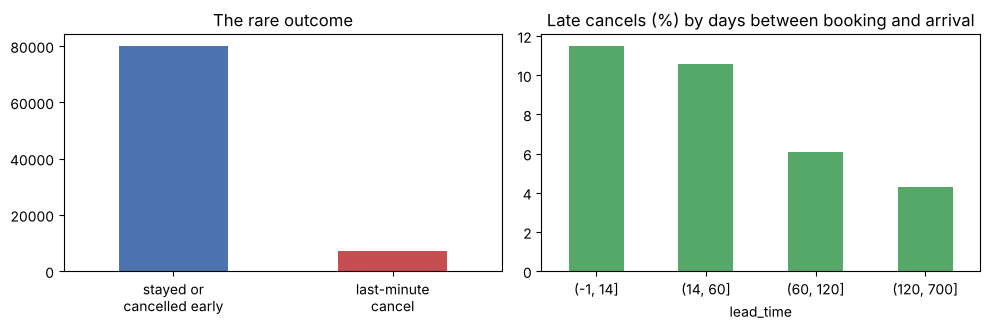

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
data.last_minute_cancel.value_counts().sort_index().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"], rot=0)
ax[0].set_xticklabels(["stayed or\ncancelled early", "last-minute\ncancel"]); ax[0].set_title("The rare outcome"); ax[0].set_xlabel("")
data.groupby(pd.cut(data.lead_time, [-1, 14, 60, 120, 700]), observed=False).last_minute_cancel.mean().mul(100).plot.bar(ax=ax[1], color="#55A868", rot=0)
ax[1].set_title("Late cancels (%) by days between booking and arrival"); ax[1].set_xlabel("lead_time")
plt.tight_layout(); plt.show()

## Part 5 · Build the model, one idea at a time
### 5a · Choose what the model may see
A model may only use facts the host knows **when the booking is made**. These are our features. Everything that happens *after* booking stays out.

In [ ]:
NUMERIC = ["lead_time", "adults", "children", "babies", "stays_in_weekend_nights", "stays_in_week_nights",
           "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
           "days_in_waiting_list", "adr", "arrival_month"]
CATEGORICAL = ["hotel", "meal", "market_segment", "distribution_channel", "reserved_room_type",
               "deposit_type", "customer_type"]

NOT_USED = ["is_canceled", "reservation_status", "reservation_status_date", "assigned_room_type",
            "booking_changes", "required_car_parking_spaces", "total_of_special_requests"]
print("Columns we deliberately leave out for now:", NOT_USED)

Columns we deliberately leave out for now: ['is_canceled', 'reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'required_car_parking_spaces', 'total_of_special_requests']


### 5b · Split the bookings: train and test
**What this code does:** it hides 30% of bookings (the **test set**). `stratify` keeps the share of late cancels the same in both parts, which matters when the outcome is rare.

In [ ]:
y = data["last_minute_cancel"]
train_idx, test_idx = train_test_split(data.index, test_size=0.3, random_state=SEED, stratify=y)
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
print("train bookings:", len(train_idx), "| test bookings:", len(test_idx))
print(f"late-cancel share  train {y_train.mean():.2%}  test {y_test.mean():.2%}")
assert all(i in test_idx for i in AI_ROWS), "our 20 bookings must be in the hidden test set"

train bookings: 61177 | test bookings: 26219
late-cancel share  train 8.35%  test 8.35%


**Checkpoint ✅** `train bookings: 61177 | test bookings: 26219`. Our 20 bookings are all inside the hidden 30%.

### 5c · The baseline: "nobody will cancel"
**What this code does:** predicts "no late cancel" for every test booking.

In [ ]:
base_pred = np.zeros(len(test_idx), dtype=int)
baseline_accuracy = accuracy_score(y_test, base_pred)
print(f"Accuracy of 'nobody will cancel': {baseline_accuracy:.2%}")
print(f"Late cancels it catches: {recall_score(y_test, base_pred):.0%}")

Accuracy of 'nobody will cancel': 91.65%
Late cancels it catches: 0%


**What it means:** doing nothing is already about 92% accurate and catches 0% of what we care about. Any model must be judged against that, not against 50%.

### 5d · Prepare the model's input table
**What this code does:** text columns (market segment, deposit type, ...) become yes/no columns, one per value.

In [ ]:
def design(df):
    return pd.get_dummies(df[NUMERIC + CATEGORICAL], columns=CATEGORICAL).astype(float)

X = design(data)
print("input table:", X.shape)

input table: (87396, 49)


**Checkpoint ✅** `input table: (87396, 49)`

### 5e · Train, then score at the default cut-off
**What this code does:** a **random forest** is 200 decision trees that each see part of the data and then vote. The share of trees voting "cancel" is the booking's **risk score** between 0 and 1. A **threshold** (cut-off) turns the score into a yes/no flag. The default is 0.5.

In [ ]:
forest = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
forest.fit(X.loc[train_idx], y_train)
risk = pd.Series(forest.predict_proba(X.loc[test_idx])[:, 1], index=test_idx)     # risk score per test booking

flag = (risk >= 0.5).astype(int)
print(f"Accuracy at cut-off 0.5 : {accuracy_score(y_test, flag):.2%}   (baseline {baseline_accuracy:.2%})")
print(f"Precision               : {precision_score(y_test, flag, zero_division=0):.1%}")
print(f"Recall                  : {recall_score(y_test, flag):.1%}")
print("\nconfusion matrix [rows: really late-cancelled? 0/1, columns: flagged? 0/1]")
print(confusion_matrix(y_test, flag))

Accuracy at cut-off 0.5 : 91.85%   (baseline 91.65%)
Precision               : 82.7%
Recall                  : 3.1%

confusion matrix [rows: really late-cancelled? 0/1, columns: flagged? 0/1]
[[24015    14]
 [ 2123    67]]


**Checkpoint ✅** `Accuracy at cut-off 0.5: 91.85%` (baseline 91.65%) · `Precision 82.7%` · `Recall 3.1%`

**Discuss:** the model is *slightly more accurate* than doing nothing, and it catches only **3 in 100** late cancels. Accuracy hid that. When the host uses this model at 0.5, almost every late cancel still arrives as a surprise.

## Part 6 · Precision and recall: the cut-off is a choice
The risk scores are the same. Only the cut-off changes. A **lower** cut-off flags more bookings.

In [ ]:
def report(thr):
    f = (risk >= thr).astype(int)
    return {"cut-off": thr,
            "flagged": f"{f.mean():.1%}",
            "precision": round(precision_score(y_test, f, zero_division=0), 3),
            "recall": round(recall_score(y_test, f), 3),
            "accuracy": round(accuracy_score(y_test, f), 3)}

table = pd.DataFrame([report(t) for t in [0.5, 0.3, 0.2, 0.15, 0.10, 0.07]]).set_index("cut-off")
print(table.to_string())

        flagged  precision  recall  accuracy
cut-off                                     
0.50       0.3%      0.827   0.031     0.918
0.30       0.9%      0.612   0.068     0.919
0.20       5.1%      0.337   0.208     0.900
0.15      11.4%      0.262   0.358     0.862
0.10      28.0%      0.176   0.589     0.735
0.07      47.6%      0.134   0.764     0.568


**Read one row in host words.** At cut-off **0.10**: the host asks **28%** of guests for a deposit; about **18 in 100** of them really would have cancelled late (precision); and the plan catches **59%** of all late cancels (recall). Lower cut-off, more cancels caught, more guests bothered.

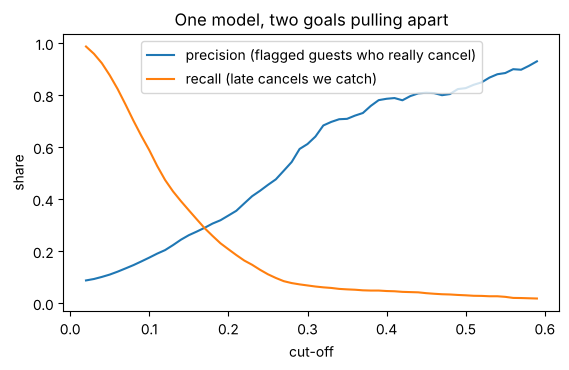

In [ ]:
cuts = np.round(np.arange(2, 60) / 100, 2)
prec = [precision_score(y_test, (risk >= t).astype(int), zero_division=0) for t in cuts]
rec = [recall_score(y_test, (risk >= t).astype(int)) for t in cuts]
plt.figure(figsize=(6.4, 3.6))
plt.plot(cuts, prec, label="precision (flagged guests who really cancel)")
plt.plot(cuts, rec, label="recall (late cancels we catch)")
plt.xlabel("cut-off"); plt.ylabel("share"); plt.legend(); plt.title("One model, two goals pulling apart"); plt.show()

**You do:** from the table, pick the **highest** cut-off that still catches **at least half** (50%) of the late cancels.

In [ ]:
threshold = 0.10
print(report(threshold))

{'cut-off': 0.1, 'flagged': '28.0%', 'precision': 0.176, 'recall': 0.589, 'accuracy': 0.735}


## Part 7 · Choose the cut-off from the cost of mistakes
The right cut-off is not a statistics question. It depends on what each mistake costs the host. We **assume** two costs. They are teaching assumptions, not facts from the data. You can change them.

* **Missing** a late cancel = an empty night nobody can refill: **₹5,000**.
* **Asking** a guest for a deposit who would **not** have cancelled = friction, some guests walk away: **₹500**.
* Asking a guest who **would** have cancelled costs nothing: the deposit covers the empty night.

In [ ]:
COST_MISS = 5000
COST_ASK = 500

def cost_per_1000(flag, cost_miss=COST_MISS, cost_ask=COST_ASK):
    flag = np.asarray(flag).astype(bool); truth = y_test.values == 1
    missed = (~flag & truth).sum()
    needless = (flag & ~truth).sum()
    return (missed * cost_miss + needless * cost_ask) / len(truth) * 1000

ask_everyone = cost_per_1000(np.ones(len(risk)))
ask_nobody = cost_per_1000(np.zeros(len(risk)))
print(f"Ask every guest for a deposit : ₹{ask_everyone:,.0f} per 1,000 bookings")
print(f"Ask nobody                    : ₹{ask_nobody:,.0f} per 1,000 bookings")

Ask every guest for a deposit : ₹458,236 per 1,000 bookings
Ask nobody                    : ₹417,636 per 1,000 bookings


Best cut-off with our costs: 0.1  ->  ₹287,254 per 1,000 bookings


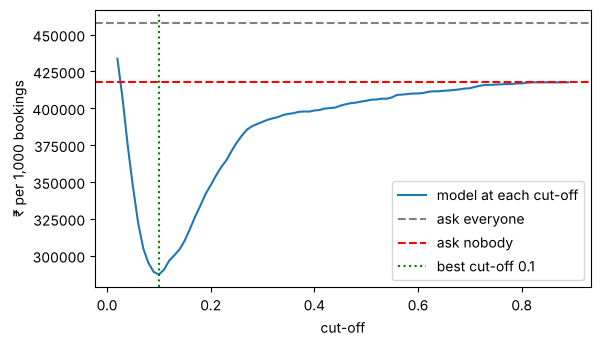

In [ ]:
GRID = np.round(np.arange(2, 90) / 100, 2)

def best_threshold(cost_miss, cost_ask):
    costs = [cost_per_1000(risk.values >= t, cost_miss, cost_ask) for t in GRID]
    i = int(np.argmin(costs))
    return float(GRID[i]), round(costs[i])

best_t, best_cost = best_threshold(COST_MISS, COST_ASK)
print(f"Best cut-off with our costs: {best_t}  ->  ₹{best_cost:,} per 1,000 bookings")

curve = [cost_per_1000(risk.values >= t) for t in GRID]
plt.figure(figsize=(6.4, 3.6))
plt.plot(GRID, curve, label="model at each cut-off")
plt.axhline(ask_everyone, color="grey", ls="--", label="ask everyone")
plt.axhline(ask_nobody, color="red", ls="--", label="ask nobody")
plt.axvline(best_t, color="green", ls=":", label=f"best cut-off {best_t}")
plt.xlabel("cut-off"); plt.ylabel("₹ per 1,000 bookings"); plt.legend(); plt.show()

**Checkpoint ✅** `Ask every guest ₹458,236 · Ask nobody ₹417,636 · Best cut-off 0.1 -> ₹287,254`

The model beats both easy options, but only by choosing the cut-off from the costs. Now change the costs. **You do:** what if asking a guest costs only **₹250**?

In [ ]:
print("asking costs 250   ->", best_threshold(5000, 250))
print("asking costs 1000  ->", best_threshold(5000, 1000))

asking costs 250   -> (0.06, 197900)
asking costs 1000  -> (0.15, 352531)


**Discuss:** when asking is cheap, the best cut-off drops and we flag more guests. When asking is expensive, it rises. **Same model, different decision.** The ratio of the two costs sets the cut-off.

## Part 8 · Is the score real? Test for leakage
**Data leakage** means the model got to see something it could not know when the prediction was needed. Scores look wonderful, then collapse in real use.

**Test 1: add one tempting column.** `reservation_status` says Check-Out, Canceled or No-Show. It sits in the same file, so it is easy to include.

In [ ]:
def fit_and_score(feature_table, thr=0.3, train=train_idx, test=test_idx, target=y):
    m = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
    m.fit(feature_table.loc[train], target.loc[train])
    p = m.predict_proba(feature_table.loc[test])[:, 1]
    f = (p >= thr).astype(int)
    return round(precision_score(target.loc[test], f, zero_division=0), 3), round(recall_score(target.loc[test], f), 3)

X_leaky = X.join(pd.get_dummies(data["reservation_status"], prefix="status").astype(float))
real = fit_and_score(X)
leaky = fit_and_score(X_leaky)
print(pd.DataFrame({"precision": [real[0], leaky[0]], "recall": [real[1], leaky[1]]},
                   index=["honest model (booking-time facts)", "+ reservation_status"]).to_string())

                                   precision  recall
honest model (booking-time facts)      0.612   0.068
+ reservation_status                   0.732   0.711


**Checkpoint ✅** at cut-off 0.3: honest model precision `0.612`, recall `0.068`. With `reservation_status`: precision `0.732`, recall `0.711`.

**Say it:** recall jumped about ten times (0.068 to 0.711). The model did not get smarter. `reservation_status` records *that the booking was cancelled*. It is the answer, handed over after the fact.

**Test 2 (optional, after class): a quieter leak, duplicate rows.** Earlier we dropped 31,994 identical rows. What if we had kept them?

In [ ]:
dup = bookings.copy()
d_arrival = pd.to_datetime(dict(year=dup.arrival_date_year, month=dup.arrival_date_month.map(MONTHS), day=dup.arrival_date_day_of_month))
d_days = (d_arrival - pd.to_datetime(dup.reservation_status_date)).dt.days
dup["y"] = ((dup.is_canceled == 1) & (d_days <= 14)).astype(int)
dup["arrival_month"] = dup.arrival_date_month.map(MONTHS)
dup["children"] = dup["children"].fillna(0)
X_dup = design(dup)
tr_d, te_d = train_test_split(dup.index, test_size=0.3, random_state=SEED, stratify=dup["y"])
with_dups = fit_and_score(X_dup, train=tr_d, test=te_d, target=dup["y"])
print(pd.DataFrame({"precision": [real[0], with_dups[0]], "recall": [real[1], with_dups[1]]},
                   index=["duplicates removed (our model)", "duplicates kept"]).to_string())

                                precision  recall
duplicates removed (our model)      0.612   0.068
duplicates kept                     0.743   0.251


**Checkpoint ✅** with duplicates kept at cut-off 0.3: precision `0.743`, recall `0.251`.

Identical bookings landed in both train and test, so the model "recognised" them. Real caveat: some identical rows are genuine group bookings, so this is a judgement call. What is certain is that **how you treat copies changes the score**.

**You do: the audit.** For each column ask: **would the host know this when the booking is made?** `"Y"` or `"N"`.

In [ ]:
audit_columns = ["lead_time", "deposit_type", "market_segment", "adults",
                 "reservation_status", "reservation_status_date", "is_canceled", "days_in_waiting_list"]
audit = ["Y", "Y", "Y", "Y", "N", "N", "N", "Y"]

code_ = hashlib.sha256("".join(audit).encode()).hexdigest()[:8]
print("your code:", code_)
print("matches the key" if code_ == '908a6d55' else "not yet: for each column, picture the moment the booking is made")

your code: 908a6d55
matches the key


**Discuss:** `reservation_status_date` was *our own* input for building the answer column in Part 4. Using it to build the target is fine. Using it as a feature would be a leak. **The same column can be legitimate in one place and a leak in another.**

Our honest model, with leakage removed and duplicates handled, is the one we trust: **precision about 18% and recall about 59% at cut-off 0.10**.

## Part 9 · The model against the AI, then check the AI's advice
### 9a · The same 20 bookings

In [ ]:
top3_model = risk.loc[AI_ROWS].sort_values(ascending=False).head(3).index.tolist()
board = pd.DataFrame({
    "booking_id": range(1, 21),
    "cancelled_late": check["cancelled_late"].values,
    "model risk score": risk.loc[AI_ROWS].round(3).values,
    "AI picked": [i in AI_PICKS for i in AI_ROWS],
    "model top 3": [i in top3_model for i in AI_ROWS],
}, index=AI_ROWS).set_index("booking_id")
print(board.sort_values("model risk score", ascending=False).head(6).to_string())
print("\nlate cancels caught in the AI's top 3   :", int(board.loc[board["AI picked"], "cancelled_late"].sum()), "of 2")
print("late cancels caught in the model's top 3:", int(board.loc[board["model top 3"], "cancelled_late"].sum()), "of 2")

            cancelled_late  model risk score  AI picked  model top 3
booking_id                                                          
12                       1             0.812      False         True
20                       0             0.347      False         True
18                       0             0.257      False         True
5                        1             0.198      False        False
17                       0             0.194      False        False
9                        0             0.142      False        False

late cancels caught in the AI's top 3   : 0 of 2
late cancels caught in the model's top 3: 1 of 2


**Careful.** Twenty bookings with two cancels is a very small exam. The honest numbers are the ones on **26,219 test bookings**. What to notice is what each gives you: the model comes with a **measured** precision and recall; the AI's pick comes with confidence and nothing to check.

### 9b · Facts for the AI
We give an AI **only the numbers we verified**, and ask for a host's action note.

In [ ]:
r10, r30 = report(0.10), report(0.30)
facts = {
    "test_bookings": len(test_idx),
    "late_cancel_share_pct": round(y_test.mean() * 100, 1),
    "baseline_accuracy_pct": round(baseline_accuracy * 100, 2),
    "model_accuracy_at_0_5_pct": round(accuracy_score(y_test, (risk >= 0.5).astype(int)) * 100, 2),
    "recall_at_0_5_pct": round(recall_score(y_test, (risk >= 0.5).astype(int)) * 100),
    "cutoff_chosen": 0.1,
    "flagged_at_chosen_pct": round(float(r10["flagged"].strip("%"))),
    "precision_at_chosen_pct": round(r10["precision"] * 100),
    "recall_at_chosen_pct": round(r10["recall"] * 100),
    "cutoff_high": 0.3,
    "recall_at_high_pct": round(r30["recall"] * 100),
    "cost_per_1000_bookings": 1000,
    "cost_ask_nobody": round(ask_nobody),
    "cost_ask_everyone": round(ask_everyone),
    "cost_model_best": best_cost,
    "assumed_cost_missed_cancel": COST_MISS,
    "assumed_cost_unneeded_deposit_request": COST_ASK,
}
for k, v in facts.items():
    print(f"{k:42s} {v}")

test_bookings                              26219
late_cancel_share_pct                      8.4
baseline_accuracy_pct                      91.65
model_accuracy_at_0_5_pct                  91.85
recall_at_0_5_pct                          3
cutoff_chosen                              0.1
flagged_at_chosen_pct                      28
precision_at_chosen_pct                    18
recall_at_chosen_pct                       59
cutoff_high                                0.3
recall_at_high_pct                         7
cost_per_1000_bookings                     1000
cost_ask_nobody                            417636
cost_ask_everyone                          458236
cost_model_best                            287254
assumed_cost_missed_cancel                 5000
assumed_cost_unneeded_deposit_request      500


In [ ]:
FACT_SHEET = f"""Verified results from a random-forest model that predicts LAST-MINUTE cancellations (cancelled 14 days or fewer before arrival) for hotel bookings. It was trained on 61,177 bookings and tested on {facts['test_bookings']:,} unseen bookings from Portugal, 2015 to 2017 (a stand-in for Airbnb data). It uses only facts known when the booking is made.
- Share of bookings that are last-minute cancels: {facts['late_cancel_share_pct']}%
- Accuracy of a rule that says nobody will cancel: {facts['baseline_accuracy_pct']}%
- Model accuracy at the default cut-off 0.5: {facts['model_accuracy_at_0_5_pct']}%, catching {facts['recall_at_0_5_pct']}% of last-minute cancels
- At cut-off {facts['cutoff_chosen']}: flags {facts['flagged_at_chosen_pct']}% of bookings, {facts['precision_at_chosen_pct']}% of flagged bookings really cancel late (precision), catches {facts['recall_at_chosen_pct']}% of all last-minute cancels (recall)
- At cut-off {facts['cutoff_high']}: catches {facts['recall_at_high_pct']}% of last-minute cancels
- ASSUMED costs (not from the data): a missed last-minute cancel costs Rs {facts['assumed_cost_missed_cancel']:,}; asking a guest who would not have cancelled for a deposit costs Rs {facts['assumed_cost_unneeded_deposit_request']:,}
- Cost per {facts['cost_per_1000_bookings']:,} bookings: ask nobody Rs {facts['cost_ask_nobody']:,}; ask everyone Rs {facts['cost_ask_everyone']:,}; model at cut-off {facts['cutoff_chosen']} Rs {facts['cost_model_best']:,}
Not tested: whether it holds on future bookings, whether deposits change guest behaviour, any reason WHY guests cancel."""

PROMPT = FACT_SHEET + """

Write a short action note (about 8 sentences) for a host: should they ask for deposits, which bookings, how much to trust the model, and what it will save. Use only the facts above."""
print(PROMPT)

Verified results from a random-forest model that predicts LAST-MINUTE cancellations (cancelled 14 days or fewer before arrival) for hotel bookings. It was trained on 61,177 bookings and tested on 26,219 unseen bookings from Portugal, 2015 to 2017 (a stand-in for Airbnb data). It uses only facts known when the booking is made.
- Share of bookings that are last-minute cancels: 8.4%
- Accuracy of a rule that says nobody will cancel: 91.65%
- Model accuracy at the default cut-off 0.5: 91.85%, catching 3% of last-minute cancels
- At cut-off 0.1: flags 28% of bookings, 18% of flagged bookings really cancel late (precision), catches 59% of all last-minute cancels (recall)
- At cut-off 0.3: catches 7% of last-minute cancels
- ASSUMED costs (not from the data): a missed last-minute cancel costs Rs 5,000; asking a guest who would not have cancelled for a deposit costs Rs 500
- Cost per 1,000 bookings: ask nobody Rs 417,636; ask everyone Rs 458,236; model at cut-off 0.1 Rs 287,254
Not tested: whe

### Note A: the same pre-written AI note for everybody
Live AI answers differ from run to run, so we check one **fixed** note first.

In [ ]:
NOTE_A = [
    f"A rule that says nobody will cancel would already be {facts['baseline_accuracy_pct']}% accurate.",
    f"Our model's {facts['model_accuracy_at_0_5_pct']}% accuracy proves it is excellent at spotting cancellations.",
    f"At a cut-off of {facts['cutoff_chosen']} the model flags {facts['flagged_at_chosen_pct']}% of bookings and catches {facts['recall_at_chosen_pct']}% of the last-minute cancels.",
    f"About {facts['recall_at_chosen_pct']}% of the bookings it flags at {facts['cutoff_chosen']} will really cancel late.",
    f"With our assumed costs, asking only flagged guests for a deposit costs about ₹{round(facts['cost_model_best'], -3):,} per {facts['cost_per_1000_bookings']:,} bookings, against ₹{round(facts['cost_ask_nobody'], -3):,} for asking nobody.",
    "Long lead times cause cancellations, so capping the booking window at 60 days would cut last-minute cancels by 30%.",
    "Guests from Portugal are the riskiest to host.",
    f"Raising the cut-off to {facts['cutoff_high']} cuts the share of last-minute cancels caught to {facts['recall_at_high_pct']}%.",
]
for i, s in enumerate(NOTE_A, 1):
    print(f"{i}. {s}")

1. A rule that says nobody will cancel would already be 91.65% accurate.
2. Our model's 91.85% accuracy proves it is excellent at spotting cancellations.
3. At a cut-off of 0.1 the model flags 28% of bookings and catches 59% of the last-minute cancels.
4. About 59% of the bookings it flags at 0.1 will really cancel late.
5. With our assumed costs, asking only flagged guests for a deposit costs about ₹287,000 per 1,000 bookings, against ₹418,000 for asking nobody.
6. Long lead times cause cancellations, so capping the booking window at 60 days would cut last-minute cancels by 30%.
7. Guests from Portugal are the riskiest to host.
8. Raising the cut-off to 0.3 cuts the share of last-minute cancels caught to 7%.


**Audit step 1: the number checker.** It lists every number in a note that does **not** appear in our verified facts.

In [ ]:
def flag_unsupported_numbers(text, facts, tolerance=0.005):
    allowed = []
    for v in facts.values():
        allowed += [abs(float(v)), abs(float(v)) * 100]
    found = re.findall(r"\d[\d,]*\.?\d*", text)
    unsupported = []
    for token in found:
        n = float(token.replace(",", "").rstrip("."))
        if not any(abs(n - a) <= max(tolerance * a, 0.5) for a in allowed):
            unsupported.append(token)
    return unsupported

for i, s in enumerate(NOTE_A, 1):
    flagged = flag_unsupported_numbers(s, facts)
    print(f"sentence {i}: {'numbers NOT in our facts -> ' + str(flagged) if flagged else 'all numbers match our facts'}")

sentence 1: all numbers match our facts
sentence 2: all numbers match our facts
sentence 3: all numbers match our facts
sentence 4: all numbers match our facts
sentence 5: all numbers match our facts
sentence 6: numbers NOT in our facts -> ['60']
sentence 7: all numbers match our facts
sentence 8: all numbers match our facts


**Audit step 2 (You do): the real test.** A matching number is not the same as a supported claim. For each sentence decide: `"B"` = **B**acked by our model results, or `"N"` = **N**ot backed.
*Ask for each: which line of our output proves this? Is it about what the model measured, or about something it never saw?*

In [ ]:
verdicts = ["B", "N", "B", "N", "B", "N", "N", "B"]      # sentences 1 to 8

answer = hashlib.sha256("".join(verdicts).encode()).hexdigest()[:8]
print("your code:", answer)
print("matches the key" if answer == 'af20973b' else "not yet: re-check sentences that sound confident")

your code: af20973b
matches the key


**Discuss in pairs (2 minutes):**
* Sentence 2: the accuracy number is real. Why does it not prove the claim? *(Compare with sentence 1.)*
* Sentence 4: the number is real, but it answers a different question. *(Precision or recall?)*
* Sentences 6 and 7: where in our output is the evidence? *(Does the model show **why** guests cancel? Is country even an input?)*

### Note B (optional, after class): ask ChatGPT or Claude yourself
1. Run `print(PROMPT)` above and copy the whole prompt.
2. Paste it into ChatGPT or Claude in another tab.
3. Paste the answer between the triple quotes below and run the cell.
4. Mark each sentence yourself, as you did for Note A.

Your answer will not match your neighbour's. That is the point: **never trust the wording, check the facts.**

In [ ]:
live_note = """
paste the AI's answer here
"""

if live_note.strip().startswith("paste the AI"):
    print("Nothing pasted yet. Carry on with Note A.")
else:
    print("Numbers not in our facts:", flag_unsupported_numbers(live_note, facts))

Nothing pasted yet. Carry on with Note A.


## Final · Your recommendation
Write the answer for the host: **which cut-off, and what to do with flagged bookings**, with two numbers from *your* output as evidence, and one thing the model cannot tell the host.

In [ ]:
my_recommendation = """
Cut-off and action: ____
Evidence 1: ____
Evidence 2: ____
What this model cannot tell the host: ____
"""
print(my_recommendation)


Cut-off and action: ____
Evidence 1: ____
Evidence 2: ____
What this model cannot tell the host: ____

